# Figure 3 and Table II — projected correlation functions and power-law fits

Measured $w_{\rm p}(r_{\rm p})$ for the full, star-forming and quenched samples with
the fitted power laws, forward-projected to $\pi_{\max}=40\,h^{-1}$Mpc.

The measured values and the published uncertainties are listed in the notebook
(also in `data/wp_measured.json`).  Figure:
`figures/fit_w_SF_vs_Q.{png,pdf}`.

In [5]:
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]   # so Jupyter finds the TeX binaries

import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "text.latex.preamble": r"\usepackage{amsmath}",
    "font.size": 11,
})

In [6]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.70

# power-law fits, r0 in PHYSICAL Mpc
F = {
    "all": (8.532209, 1.781478),
    "SS":  (6.591951, 1.587474),   # SF x SF
    "QQ":  (10.521289, 1.950136),  # Q  x Q
}

# population fractions from the same parent (N_SF = 39112, N_Q = 35659)
f_SF = 0.5230905030025009
f_Q  = 0.4769094969974990

In [7]:
from scipy.integrate import quad

# --- measured w_p (uniform-in-comoving-volume randoms, bright0 parent) -----------------
rp = np.array([0.1217, 0.1730, 0.2468, 0.3510, 0.5006, 0.7120, 1.0139, 1.4446,
               2.0577, 2.9321, 4.1742, 5.9412, 8.4639, 12.0460, 17.1579])   # h^-1 Mpc
WP = {
 "all": np.array([406.51, 324.01, 250.13, 197.86, 153.52, 117.76, 85.86, 61.88,
                  46.39, 35.78, 27.67, 20.48, 14.27, 9.53, 5.34]),
 "SS":  np.array([170.73, 140.20, 107.65, 93.90, 71.28, 61.31, 47.43, 37.36,
                  29.93, 24.52, 20.00, 15.23, 10.74, 7.33, 4.03]),
 "QQ":  np.array([937.05, 718.31, 545.93, 417.35, 317.21, 228.92, 155.63, 104.52,
                  73.21, 52.56, 38.02, 27.28, 18.84, 12.66, 7.32]),
}
# published diagonal errors, used as the fit weights
EP = {
 "all": np.array([18.80,15.07,14.57,13.40,11.28,9.41,7.57,5.95,5.09,4.15,3.49,2.91,2.19,1.56,1.28]),
 "SS":  np.array([9.52,7.47,5.66,4.97,3.61,3.19,2.62,2.40,2.38,2.29,2.11,1.98,1.55,1.23,1.06]),
 "QQ":  np.array([55.17,42.57,40.38,35.66,28.37,23.97,18.02,12.78,10.07,7.36,5.69,4.39,3.18,2.17,1.66]),
}
PIMAX  = 40.0     # h^-1 Mpc, as in the measurement
RP_MIN = 0.3      # primary fit range lower edge, h^-1 Mpc

# r0 back to h^-1 Mpc (F stores physical Mpc)
F_h = {k: (v[0]*h, v[1]) for k, v in F.items()}

def wp_model(r_p, r0, g, pimax=PIMAX):
    """w_p = 2 * int_0^pimax xi(sqrt(rp^2+pi^2)) dpi  -- finite pi, not the pi->inf form."""
    return np.array([2*quad(lambda p: (np.hypot(x, p)/r0)**(-g), 0, pimax, limit=200)[0]
                     for x in np.atleast_1d(r_p)])


Table II: power-law fits, r0 in h^-1 Mpc
   all r0 =  5.97   gamma = 1.78
   SF  r0 =  4.61   gamma = 1.59
   Q   r0 =  7.36   gamma = 1.95


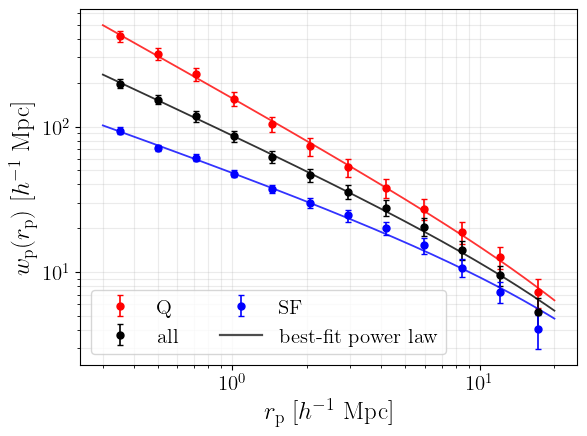

In [8]:
C   = {"all": "black", "SS": "blue", "QQ": "red"}
LBL = {"all": "all", "SS": "SF", "QQ": "Q"}
fit = rp >= RP_MIN                       # only the primary fit range is shown
rr  = np.logspace(np.log10(RP_MIN), np.log10(20.0), 200)

print("Table II: power-law fits, r0 in h^-1 Mpc")
for k in ("all", "SS", "QQ"):
    print("   %-3s r0 = %5.2f   gamma = %.2f" % (LBL[k], *F_h[k]))

import os
from pathlib import Path
FIG = Path(os.environ.get("HOSTINFER_FIGDIR", "figures"))
if not FIG.is_dir(): FIG = Path("..")/"figures"
FIG.mkdir(parents=True, exist_ok=True)
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6, 4.5))
for k in ("QQ", "all", "SS"):
    ax.errorbar(rp[fit], WP[k][fit], yerr=EP[k][fit], fmt="o", ms=5, color=C[k],
                capsize=2, lw=1.2, label=LBL[k])
    ax.plot(rr, wp_model(rr, *F_h[k]), "-", color=C[k], lw=1.3, alpha=.8)

hs, ls_ = ax.get_legend_handles_labels()
style = [
         Line2D([], [], color="0.3", ls="-", lw=1.6)]
ax.legend(hs + style, ls_ + ["best-fit power law"],
          fontsize=15, ncol=2)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylabel(r"$w_{\rm p}(r_{\rm p})$  [$h^{-1}$ Mpc]", fontsize=18)
ax.set_xlabel(r"$r_{\rm p}$  [$h^{-1}$ Mpc]", fontsize=18)
ax.grid(alpha=.25, which="both")
ax.tick_params(axis="both", which="major", labelsize=15)
fig.tight_layout()
fig.savefig(FIG/"fit_w_SF_vs_Q.png", dpi=170)
fig.savefig(FIG/"fit_w_SF_vs_Q.pdf")
plt.show()